In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# TP — Classification de feuilles (**lisse vs dentée**) avec PyTorch

**Objectif** : construire pas à pas un classifieur d'images binaire (feuille *lisse* vs *dentée*) avec PyTorch.
Vous implémenterez :
1) le chargement des données avec `ImageFolder` et un **split stratifié** train/val/test,  
2) un **CNN** simple,  
3) une **boucle d'entraînement** + **évaluation** complète,  
4) les **métriques** (accuracy, precision, recall, f1, log-loss, AUC-ROC),  
5) les figures : **matrice de confusion**, **courbe ROC**, **Precision–Recall**.

> Placez vos images dans un dossier structuré :  
`data/feuilles/`  
├── `dentee/` (ou `dentee`)  
└── `lisse/`  
(Chaque sous-dossier contient des images `.jpg/.png`.)

Les cellules marquées `# TODO` sont à **compléter**.


In [3]:
# 🔧 Imports & configuration
import os, random, math, time
from dataclasses import dataclass
from typing import Tuple, List

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             balanced_accuracy_score, cohen_kappa_score,
                             log_loss, roc_auc_score, classification_report,
                             confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay,
                             ConfusionMatrixDisplay)

# Reproductibilité
torch.manual_seed(0); random.seed(0); np.random.seed(0)

# Device (GPU si dispo)
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
device


device(type='cuda')

## 1) Données & Transformations

1. Définissez le chemin `DATA_DIR` vers votre dossier `data/feuilles`.
2. Créez des **transformations** pour l'entraînement et la validation/test (redimensionnement, normalisation).
3. Chargez le dataset avec `datasets.ImageFolder`.


In [ ]:
# === Imports nécessaires ===
import os
import random
import torch
from torchvision import transforms, datasets

# Reproductibilité
seed = 42
random.seed(seed)
torch.manual_seed(seed)

# === Chemin de tes données ===
DATA_DIR = "/content/drive/MyDrive/feuilles_plantes/feuilles_plantes"

# Vérification simple du dossier
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"DATA_DIR '{DATA_DIR}' introuvable. Vérifie le chemin.")

# === Transformations (train / val-test) ===
IMAGE_SIZE = 224  # Taille d'entrée pour un CNN simple
BATCH_SIZE_TRAIN = 32
BATCH_SIZE_EVAL = 64
# Normalisation standard (ImageNet) — adaptée aux images RGB
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

transform_eval = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# === Chargement du dataset ===
full_dataset = datasets.ImageFolder(DATA_DIR, transform=transform_train)
num_classes = len(full_dataset.classes)
print("✅ Classes détectées:", full_dataset.classes)
print("📸 Nombre total d’images:", len(full_dataset))


✅ Classes détectées: ['dente', 'lisse']
📸 Nombre total d’images: 6544


## 2) Split **stratifié** train/val/test

Complétez la fonction `stratified_split` qui répartit équitablement les indices par classe (ex: 70%/15%/15%).

In [ ]:
from dataclasses import dataclass
from collections import defaultdict
from typing import List
import math
import random
import torch
from torch.utils.data import Subset, DataLoader
from torchvision import datasets

@dataclass
class Splits:
    train: Subset
    val: Subset
    test: Subset

def stratified_split(dataset: datasets.ImageFolder,
                     train_ratio: float = 0.7,
                     val_ratio: float = 0.15,
                     test_ratio: float = 0.15,
                     seed: int = 0) -> Splits:
    """
    Retourne des Subsets train/val/test en respectant la proportion par classe.
    - dataset: torchvision.datasets.ImageFolder (doit contenir .targets)
    - ratios must sum (approximately) to 1.0
    """
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6, "Les ratios doivent sommer à 1.0"
    # Récupère la liste des labels (ImageFolder fournit .targets)
    targets: List[int] = dataset.targets
    n = len(targets)
    if n == 0:
        raise ValueError("Le dataset est vide.")

    # Regrouper indices par label
    idx_by_label = defaultdict(list)
    for idx, lbl in enumerate(targets):
        idx_by_label[lbl].append(idx)

    # RNG global pour reproductibilité
    rng = random.Random(seed)

    train_indices = []
    val_indices = []
    test_indices = []

    # Pour chaque classe: mélanger, couper selon ratios, puis ajouter aux lists globales
    for lbl, indices in idx_by_label.items():
        # copie et shuffle
        indices_copy = list(indices)
        rng.shuffle(indices_copy)

        L = len(indices_copy)
        n_train = int(math.floor(L * train_ratio))
        n_val   = int(math.floor(L * val_ratio))
        # assure que tout est couvert — le restant va à test
        n_test = L - n_train - n_val

        # slices
        start = 0
        train_slice = indices_copy[start:start + n_train]
        start += n_train
        val_slice   = indices_copy[start:start + n_val]
        start += n_val
        test_slice  = indices_copy[start:start + n_test]

        train_indices.extend(train_slice)
        val_indices.extend(val_slice)
        test_indices.extend(test_slice)

    # Mélange final pour éviter séquences ordonnées par classe dans les subsets
    rng.shuffle(train_indices)
    rng.shuffle(val_indices)
    rng.shuffle(test_indices)

    # Créer les Subset (ils référencent le même dataset; tu pourras changer dataset.transform plus tard)
    train_subset = Subset(dataset, train_indices)
    val_subset   = Subset(dataset, val_indices)
    test_subset  = Subset(dataset, test_indices)

    return Splits(train=train_subset, val=val_subset, test=test_subset)


# ---------------------------
# Exemple d'utilisation (adapter les noms si besoin)
# ---------------------------

# Supposons que 'full_dataset' est un ImageFolder (voir cellule précédente).
# On crée d'abord un dataset sans transform pour obtenir targets si nécessaire.
# Ici on assume full_dataset existe.

splits = stratified_split(full_dataset, 0.7, 0.15, 0.15, seed=42)

# Important : pour appliquer des transforms différents aux splits,
# on modifie `full_dataset.transform` avant de construire les DataLoaders.
# (les Subset réfèrent à `full_dataset`, donc ils verront la transform actuelle.)

# Exemple concret :
#  DataLoaders
# -------------------------------
full_dataset.transform = transform_train
train_loader = DataLoader(splits.train, batch_size=BATCH_SIZE_TRAIN, shuffle=True, num_workers=2)
full_dataset.transform = transform_eval
val_loader = DataLoader(splits.val, batch_size=BATCH_SIZE_EVAL, shuffle=False, num_workers=2)
test_loader = DataLoader(splits.test, batch_size=BATCH_SIZE_EVAL, shuffle=False, num_workers=2)

## 3) Modèle — CNN simple

Implémentez un CNN compact (2–3 blocs Conv2d→ReLU→MaxPool, puis Linear).

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SmallCNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()

        # --- Bloc convolutionnel 1 ---
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(16) # normalisation par batch
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # --- Bloc convolutionnel 2 ---
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(32)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # --- Bloc convolutionnel 3 ---
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(64)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # --- Couches fully connected ---
        # Après 3 pooling (2x2), la taille spatiale devient /8 (si entrée = 224 → 28x28)
        self.flatten_dim = 64 * 28 * 28

        self.fc1 = nn.Linear(self.flatten_dim, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        # Bloc 1
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        # Bloc 2
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        # Bloc 3
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        # Flatten
        x = x.view(x.size(0), -1)
        # Fully connected
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = SmallCNN(num_classes).to(device)
print(model)


SmallCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=50176, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


## 4) Boucle d'entraînement + évaluation intermédiaire

Écrivez `train_one_epoch` (entraînement) et `evaluate` (sans gradient) qui renvoient les pertes et les prédictions pour calculer des **métriques**.

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0

    for imgs, labels in loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        # === Forward ===
        outputs = model(imgs)

        # === Loss ===
        loss = criterion(outputs, labels)

        # === Backpropagation ===
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # === Statistiques ===
        total_loss += loss.item() * imgs.size(0)

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    y_true, y_pred, y_proba = [], [], []

    for imgs, labels in loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        # === Forward ===
        outputs = model(imgs)

        # === Loss ===
        loss = criterion(outputs, labels)

        # === Collecter labels, prédictions et probabilités ===
        probs = F.softmax(outputs, dim=1)  # Convert logits → probabilités
        preds = probs.argmax(dim=1)        # Classe la plus probable

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

        # On suppose classification binaire → proba de la classe positive (indice 1)
        if probs.shape[1] == 2:
            y_proba.extend(probs[:, 1].cpu().numpy())
        else:
            # pour multi-class, on peut stocker proba max
            y_proba.extend(probs.max(dim=1)[0].cpu().numpy())

        total_loss += loss.item() * imgs.size(0)

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, np.array(y_true), np.array(y_pred), np.array(y_proba)

# Entraînement
# -------------------------------
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
num_epochs = 15
best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):
    tr_loss = train_one_epoch(model, train_loader, optimizer, criterion)
    va_loss, y_t, y_p, y_s = evaluate(model, val_loader, criterion)
    print(f"Epoch {epoch+1:02d} | train loss: {tr_loss:.4f} | val loss: {va_loss:.4f}")
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        best_model_state = model.state_dict().copy()

model.load_state_dict(best_model_state)
print(" Meilleur modèle chargé (val_loss = {:.4f})".format(best_val_loss))



Epoch 01 | train loss: 0.9754 | val loss: 0.6081
Epoch 02 | train loss: 0.6244 | val loss: 0.5698
Epoch 03 | train loss: 0.6198 | val loss: 0.5776
Epoch 04 | train loss: 0.5916 | val loss: 0.5607
Epoch 05 | train loss: 0.5881 | val loss: 0.5458
Epoch 06 | train loss: 0.6078 | val loss: 0.5788
Epoch 07 | train loss: 0.5774 | val loss: 0.5313
Epoch 08 | train loss: 0.5476 | val loss: 0.4683
Epoch 09 | train loss: 0.5238 | val loss: 0.4838
Epoch 10 | train loss: 0.5220 | val loss: 0.4495
Epoch 11 | train loss: 0.5358 | val loss: 0.4929
Epoch 12 | train loss: 0.5203 | val loss: 0.4590
Epoch 13 | train loss: 0.5113 | val loss: 0.4956
Epoch 14 | train loss: 0.5013 | val loss: 0.4205
Epoch 15 | train loss: 0.4619 | val loss: 0.4482
✅ Meilleur modèle chargé (val_loss = 0.4205)


## 5) Métriques (val/test) + Figures

Complétez la cellule pour afficher : accuracy, precision, recall, f1, balanced accuracy, kappa, log-loss, AUC-ROC, **classification report**; puis tracer **matrice de confusion**, **ROC**, **PR**.

Test loss         : 0.4713
Accuracy          : 0.7815
Precision         : 0.9236
Recall            : 0.5915
F1                : 0.7211
Balanced Acc      : 0.7734
Cohen's Kappa     : 0.5553
Log-Loss          : 0.4713
AUC-ROC           : 0.1492

Classification report:
               precision    recall  f1-score   support

       dente       0.92      0.59      0.72       470
       lisse       0.72      0.96      0.82       514

    accuracy                           0.78       984
   macro avg       0.82      0.77      0.77       984
weighted avg       0.82      0.78      0.77       984



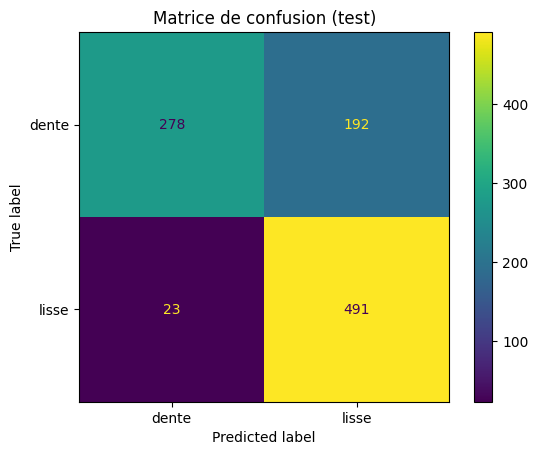

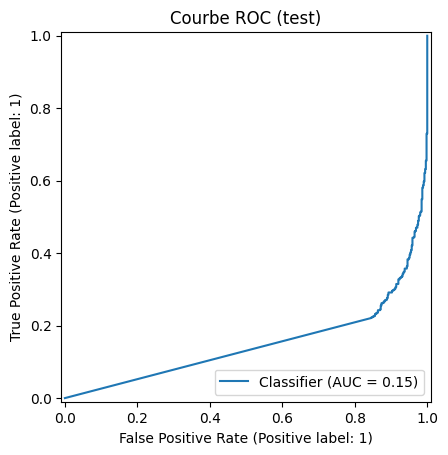

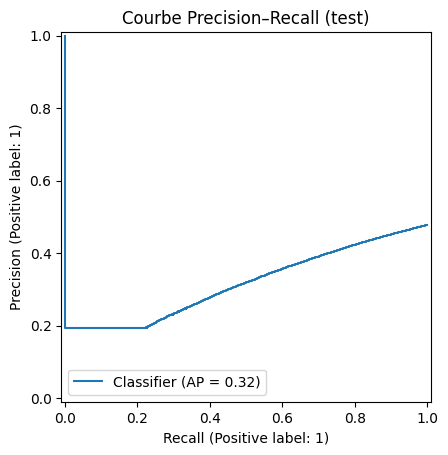

In [ ]:
te_loss, y_true, y_pred, y_proba = evaluate(model, test_loader, criterion)
pos_class_name = "dente"
pos_idx = full_dataset.classes.index(pos_class_name)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=pos_idx)
bacc = balanced_accuracy_score(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)
ll = log_loss(y_true, np.column_stack([1-y_proba, y_proba]))
auc = roc_auc_score((y_true==pos_idx).astype(int), y_proba)

print(f"Test loss         : {te_loss:.4f}")
print(f"Accuracy          : {acc:.4f}")
print(f"Precision         : {prec:.4f}")
print(f"Recall            : {rec:.4f}")
print(f"F1                : {f1:.4f}")
print(f"Balanced Acc      : {bacc:.4f}")
print(f"Cohen's Kappa     : {kappa:.4f}")
print(f"Log-Loss          : {ll:.4f}")
print(f"AUC-ROC           : {auc:.4f}")
print("\nClassification report:\n", classification_report(y_true, y_pred, target_names=full_dataset.classes))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=full_dataset.classes).plot(values_format='d')
plt.title("Matrice de confusion (test)")
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions((y_true==pos_idx).astype(int), y_proba)
plt.title("Courbe ROC (test)")
plt.show()

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions((y_true==pos_idx).astype(int), y_proba)
plt.title("Courbe Precision–Recall (test)")
plt.show()

## 6) Analyse d'erreurs (optionnel)
Affichez quelques **faux positifs** et **faux négatifs**.

In [ ]:
# TODO (optionnel): retrouver des indices d'erreurs et afficher les images correspondantes.
import matplotlib.pyplot as plt
import numpy as np

# === On récupère toutes les images et labels du test loader ===
# Note : on garde le transform_eval pour affichage
full_dataset.transform = transform_eval
test_subset = splits.test

# Créer un DataLoader sans shuffle pour garder l’ordre
display_loader = DataLoader(test_subset, batch_size=1, shuffle=False)

faux_positifs = []
faux_negatifs = []

# On parcourt le test set
model.eval()
with torch.no_grad():
    for idx, (img, label) in enumerate(display_loader):
        img_device = img.to(device)
        output = model(img_device)
        probs = F.softmax(output, dim=1)
        pred = probs.argmax(dim=1).item()

        # Vérifier si c'est une erreur
        if pred != label.item():
            if pred == pos_idx:
                faux_positifs.append((img, label.item(), pred))
            else:
                faux_negatifs.append((img, label.item(), pred))

# Fonction pour afficher quelques images
def show_images(errors_list, title, n=5):
    plt.figure(figsize=(15,3))
    for i, (img, true_label, pred_label) in enumerate(errors_list[:n]):
        img_np = img.squeeze().permute(1,2,0).cpu().numpy()
        img_np = img_np * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)  # denormalize
        img_np = np.clip(img_np, 0, 1)
        plt.subplot(1, n, i+1)
        plt.imshow(img_np)
        plt.axis('off')
        plt.title(f"V:{full_dataset.classes[true_label]}\nP:{full_dataset.classes[pred_label]}")
    plt.suptitle(title)
    plt.show()

# Affichage des faux positifs
show_images(faux_positifs, "Faux Positifs (prédit dente alors que vrai = lisse)")

# Affichage des faux négatifs
show_images(faux_negatifs, "Faux Négatifs (prédit lisse alors que vrai = dente)")


# Resnet

Classes detected: ['dente', 'lisse']
Total images: 6544


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNeXt101_32X8D_Weights.IMAGENET1K_V1`. You can also use `weights=ResNeXt101_32X8D_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnext101_32x8d-8ba56ff5.pth" to /root/.cache/torch/hub/checkpoints/resnext101_32x8d-8ba56ff5.pth


100%|██████████| 340M/340M [00:01<00:00, 206MB/s]


Epoch 01 | Train Loss: 0.1723 | Val Loss: 0.0695
Epoch 02 | Train Loss: 0.0693 | Val Loss: 0.1314
Epoch 03 | Train Loss: 0.0630 | Val Loss: 0.0535
Epoch 04 | Train Loss: 0.0306 | Val Loss: 0.0711
Epoch 05 | Train Loss: 0.0410 | Val Loss: 0.0596
Epoch 06 | Train Loss: 0.0167 | Val Loss: 0.0479
Epoch 07 | Train Loss: 0.0054 | Val Loss: 0.0391
Epoch 08 | Train Loss: 0.0084 | Val Loss: 0.0664
Epoch 09 | Train Loss: 0.0035 | Val Loss: 0.0528
Epoch 10 | Train Loss: 0.0255 | Val Loss: 0.2746
Epoch 11 | Train Loss: 0.0653 | Val Loss: 0.0558
Epoch 12 | Train Loss: 0.0064 | Val Loss: 0.0455
Epoch 13 | Train Loss: 0.0054 | Val Loss: 0.0645
Epoch 14 | Train Loss: 0.0036 | Val Loss: 0.0638
Epoch 15 | Train Loss: 0.0026 | Val Loss: 0.0537
Epoch 16 | Train Loss: 0.0009 | Val Loss: 0.0431
Epoch 17 | Train Loss: 0.0015 | Val Loss: 0.0406
Epoch 18 | Train Loss: 0.0008 | Val Loss: 0.0410
Epoch 19 | Train Loss: 0.0025 | Val Loss: 0.0419
Epoch 20 | Train Loss: 0.0055 | Val Loss: 0.0601
Best model loaded (v

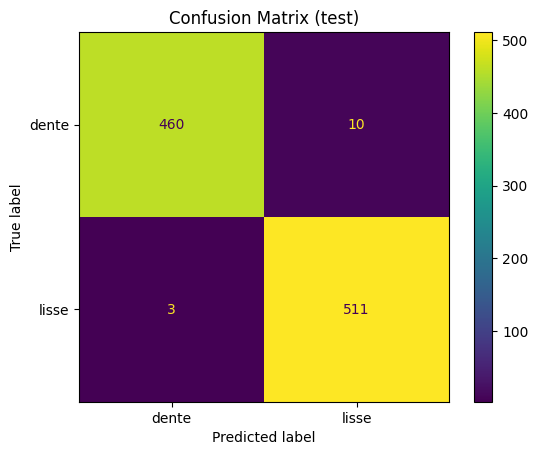

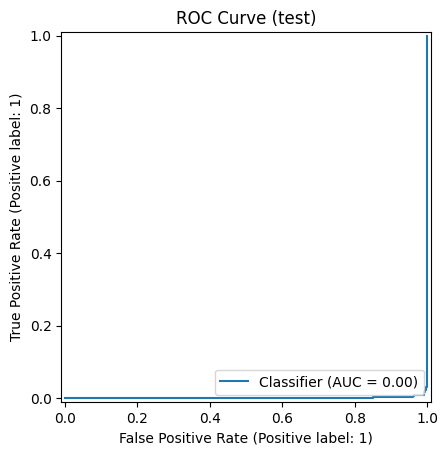

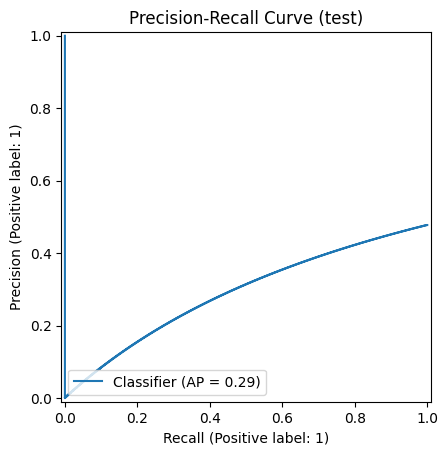

✅ Model saved to /content/resnext101_leaves.pth


In [3]:
# === Imports ===
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, balanced_accuracy_score,
    cohen_kappa_score, log_loss, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from collections import defaultdict
import random, math
from dataclasses import dataclass

# === Settings ===
seed = 42
random.seed(seed)
torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "/content/drive/MyDrive/feuilles_plantes/feuilles_plantes"
IMAGE_SIZE = 224
BATCH_SIZE_TRAIN = 32
BATCH_SIZE_EVAL = 64
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# === Data transforms ===
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3,0.3,0.3,0.1),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.2)
])

transform_eval = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# === Dataset ===
full_dataset = datasets.ImageFolder(DATA_DIR)
num_classes = len(full_dataset.classes)
print("Classes detected:", full_dataset.classes)
print("Total images:", len(full_dataset))

# === Stratified split ===
@dataclass
class Splits:
    train: Subset
    val: Subset
    test: Subset

def stratified_split(dataset, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=0):
    targets = dataset.targets
    idx_by_label = defaultdict(list)
    for idx, lbl in enumerate(targets):
        idx_by_label[lbl].append(idx)
    rng = random.Random(seed)
    train_idx, val_idx, test_idx = [], [], []
    for lbl, indices in idx_by_label.items():
        rng.shuffle(indices)
        L = len(indices)
        n_train = int(math.floor(L*train_ratio))
        n_val = int(math.floor(L*val_ratio))
        n_test = L - n_train - n_val
        start = 0
        train_idx.extend(indices[start:start+n_train])
        start += n_train
        val_idx.extend(indices[start:start+n_val])
        start += n_val
        test_idx.extend(indices[start:start+n_test])
    rng.shuffle(train_idx); rng.shuffle(val_idx); rng.shuffle(test_idx)
    return Splits(
        train=Subset(dataset, train_idx),
        val=Subset(dataset, val_idx),
        test=Subset(dataset, test_idx)
    )

splits = stratified_split(full_dataset)

# === DataLoaders ===
full_dataset.transform = transform_train
train_loader = DataLoader(splits.train, batch_size=BATCH_SIZE_TRAIN, shuffle=True, num_workers=2)
full_dataset.transform = transform_eval
val_loader = DataLoader(splits.val, batch_size=BATCH_SIZE_EVAL, shuffle=False, num_workers=2)
test_loader = DataLoader(splits.test, batch_size=BATCH_SIZE_EVAL, shuffle=False, num_workers=2)

# === Model ResNeXt-101 pretrained + fine-tuning layer3+layer4+fc ===
model = models.resnext101_32x8d(pretrained=True)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)

# Unfreeze last layers for fine-tuning
for name, param in model.named_parameters():
    param.requires_grad = False
    if "layer3" in name or "layer4" in name or "fc" in name:
        param.requires_grad = True

model = model.to(device)

# === Optimizer, criterion, scheduler ===
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# === Training Loop ===
num_epochs = 20
best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
    tr_loss = total_loss / len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss, y_t, y_p, y_s = 0, [], [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            probs = F.softmax(outputs, dim=1)
            preds = probs.argmax(dim=1)
            y_t.extend(labels.cpu().numpy())
            y_p.extend(preds.cpu().numpy())
            if probs.shape[1]==2:
                y_s.extend(probs[:,1].cpu().numpy())
            else:
                y_s.extend(probs.max(dim=1)[0].cpu().numpy())
            val_loss += loss.item() * imgs.size(0)
    va_loss = val_loss / len(val_loader.dataset)
    scheduler.step(va_loss)

    print(f"Epoch {epoch+1:02d} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}")

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        best_model_state = model.state_dict().copy()

model.load_state_dict(best_model_state)
print("Best model loaded (val_loss = {:.4f})".format(best_val_loss))





# === Evaluation on test set ===
te_loss, y_true, y_pred, y_proba = 0, [], [], []
model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        probs = F.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())
        if probs.shape[1]==2:
            y_proba.extend(probs[:,1].cpu().numpy())
        else:
            y_proba.extend(probs.max(dim=1)[0].cpu().numpy())
        te_loss += loss.item() * imgs.size(0)
te_loss /= len(test_loader.dataset)

pos_class_name = full_dataset.classes[0]  # change if needed
pos_idx = full_dataset.classes.index(pos_class_name)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=pos_idx)
bacc = balanced_accuracy_score(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)
ll = log_loss(y_true, np.column_stack([1-np.array(y_proba), np.array(y_proba)]))
auc = roc_auc_score((np.array(y_true)==pos_idx).astype(int), np.array(y_proba))

print(f"Test loss         : {te_loss:.4f}")
print(f"Accuracy          : {acc:.4f}")
print(f"Precision         : {prec:.4f}")
print(f"Recall            : {rec:.4f}")
print(f"F1                : {f1:.4f}")
print(f"Balanced Acc      : {bacc:.4f}")
print(f"Cohen's Kappa     : {kappa:.4f}")
print(f"Log-Loss          : {ll:.4f}")
print(f"AUC-ROC           : {auc:.4f}")
print("\nClassification report:\n", classification_report(y_true, y_pred, target_names=full_dataset.classes))

# === Confusion matrix and curves ===
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=full_dataset.classes).plot(values_format='d')
plt.title("Confusion Matrix (test)")
plt.show()

RocCurveDisplay.from_predictions((np.array(y_true)==pos_idx).astype(int), np.array(y_proba))
plt.title("ROC Curve (test)")
plt.show()

PrecisionRecallDisplay.from_predictions((np.array(y_true)==pos_idx).astype(int), np.array(y_proba))
plt.title("Precision-Recall Curve (test)")
plt.show()

# === Save model for Streamlit usage ===
torch.save(model.state_dict(), "/content/resnext101_leaves.pth")
print("✅ Model saved to /content/resnext101_leaves.pth")


In [5]:
from google.colab import files
files.download("/content/resnext101_leaves.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>